# Retain: an honest attrition model

This notebook reads the artifacts written by `python -m ml.train` (run `make train` first). All modelling code lives in the `ml/` package; this notebook only presents results.

The original analysis is preserved unchanged in `original.ipynb`. It trained and scored the same rows, so its numbers were inflated. This notebook shows the honest, held-out numbers next to them.

**Platform note:** the outputs below come from whichever machine last ran this notebook. XGBoost's floating-point results differ slightly between Windows and Linux even with the same pinned versions. The README and model card quote the canonical Linux run (the one CI and Docker use).

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / 'ml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from ml.data import load_raw
from ml.explain import top_drivers
from ml.features import FEATURES
from ml.paths import MODELS_DIR

metrics = json.loads((MODELS_DIR / 'metrics.json').read_text())
print('model version', metrics['version'], '| threshold', metrics['threshold'])

model version 1.0.0 | threshold 0.2235


D:\Project\Employee attrition\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Before vs after

*Before* = the original notebook (fit and scored on the same 1,470 rows, cut-off 0.9). *After* = a model that never saw the 294 test employees, with 95% bootstrap intervals.

In [2]:
keys = ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'accuracy', 'brier']
pd.DataFrame({
    'before (leaky)': [metrics['before'][k] for k in keys],
    'after (held-out)': [metrics['after'][k] for k in keys],
    '95% CI': [tuple(metrics['after']['ci'][k]) for k in keys],
}, index=keys)

,before (leaky),after (held-out),95% CI
roc_auc,0.9637,0.7949,"(0.7128, 0.8728)"
pr_auc,0.8398,0.5513,"(0.4123, 0.6907)"
precision,0.4380,0.4878,"(0.3333, 0.6389)"
recall,0.9831,0.4255,"(0.283, 0.5682)"
f1,0.6060,0.4545,"(0.3117, 0.5745)"
accuracy,0.7939,0.8367,"(0.7959, 0.8776)"
brier,0.4391,0.1029,"(0.0772, 0.1291)"


## Choosing the threshold

The cut-off is the one that maximised F1 on out-of-fold training predictions, not a hand-picked 0.9.

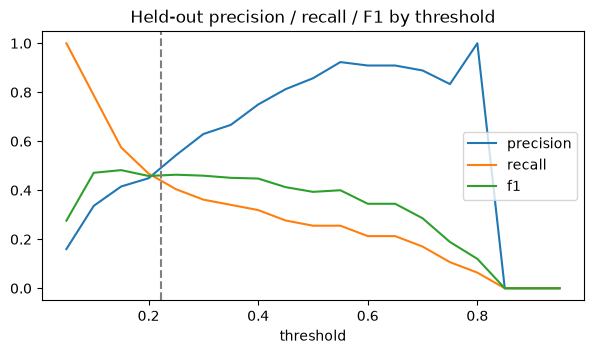

In [3]:
tc = pd.DataFrame(metrics['threshold_curve']).set_index('threshold')
ax = tc.plot(figsize=(7, 3.5), title='Held-out precision / recall / F1 by threshold')
ax.axvline(metrics['threshold'], ls='--', c='grey')
plt.show()

## Calibration

SMOTE pushes probabilities up; isotonic calibration pulls them back so a 30% risk score means roughly 30% of such people leave.

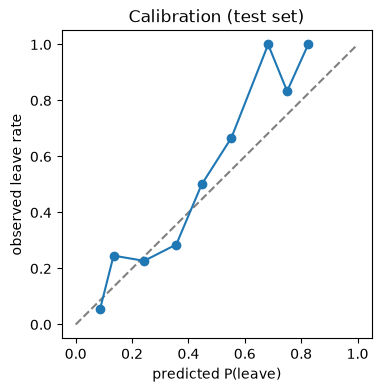

In [4]:
cal = pd.DataFrame(metrics['calibration'])
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([0, 1], [0, 1], ls='--', c='grey')
ax.plot(cal.mean_pred, cal.frac_pos, marker='o')
ax.set(xlabel='predicted P(leave)', ylabel='observed leave rate', title='Calibration (test set)')
plt.show()

## One employee, explained

Employee 1004 is scored by the fold model that never saw them. Drivers are SHAP values grouped back to the original columns. They describe how the *model* reacts, not what *causes* anyone to leave.

In [5]:
oof = pd.read_parquet(MODELS_DIR / 'oof.parquet').set_index('EmployeeID')
emp = 1004
fold = int(oof.loc[emp, 'fold'])
model = joblib.load(MODELS_DIR / f'fold_{fold}.joblib')
row = load_raw().set_index('EmployeeID').loc[[emp], FEATURES]
print(f"risk score P(leave) = {oof.loc[emp, 'risk_score']:.2f} (threshold {metrics['threshold']})")
pd.DataFrame(top_drivers(model, row))[['text', 'direction', 'impact']]

risk score P(leave) = 0.35 (threshold 0.2235)


,text,direction,impact
0,Works overtime,raises,1.3098
1,Travels frequently for work,raises,0.6549
2,"Daily rate 1,392",lowers,-0.5967
3,Workplace satisfaction: very high,lowers,-0.5621
4,No stock options,raises,0.5461


## Fairness check

Gender, age and marital status are **not** model inputs. They are used only here, to see whether the model behaves differently across groups.

In [6]:
pd.DataFrame(metrics['fairness'])

,group,value,n,attrition_rate,mean_risk,precision,recall,flag_rate,small_sample
0,Gender,Female,588,0.1480,0.1658,0.5686,0.6667,0.1735,False
1,Gender,Male,882,0.1701,0.1562,0.5143,0.4800,0.1587,False
2,AgeBand,30-39,622,0.1431,0.1475,0.5814,0.5618,0.1383,False
3,AgeBand,40-49,349,0.0974,0.1273,0.3243,0.3529,0.1060,False
4,AgeBand,50+,173,0.1329,0.1285,0.4118,0.3043,0.0983,False
5,AgeBand,<30,326,0.2791,0.2357,0.5980,0.6703,0.3129,False
6,MaritalStatus,Divorced,327,0.1009,0.1274,0.5143,0.5455,0.1070,False
7,MaritalStatus,Married,673,0.1248,0.1365,0.4167,0.4167,0.1248,False
8,MaritalStatus,Single,470,0.2553,0.2165,0.6260,0.6417,0.2617,False
